# Data Cleaning & Preparation

In [1]:
import pandas as pd
import numpy as np

#load the dataset
df=pd.read_csv(r'ecommerce_sales.csv')

# replace spredsheet errors with null or NaN and hide the index volumn if it exists 
df=df.replace(['#REF!', 'N/A', 'NA', 'null', '?', '-'], np.nan)
df=df.drop(columns=['index'])

#Clean up
df.columns = df.columns.str.strip().str.replace(' ', '_').str.replace('.', '', regex=False)
print("New Column Names:", df.columns.tolist())

#view the shape to understand the data
print('\nInitial data shape:', df.shape)

#view the first 5 rows to understand the structure
display(df.head().style.hide_index())

#check for missing values and duplicates
print('\nmissing values per column:\n', df.isnull().sum())
print('duplicate rows count:', df.duplicated().sum())

#clean the data
#drop rows where data is missing
df_clean_data=df.dropna(subset=['Stock_Keeping_Unit_code', 'Design_No', 'Stock', 'Category', 'Size', 'Color'])

#remove duplicate rows
df_clean_data=df_clean_data.drop_duplicates()

#ensure stock is represented as an integer
df_clean_data['Stock']=df_clean_data['Stock'].astype(int)

print('\ncleaned data shape:', df_clean_data.shape)

#save the clean dataset for sql querying
df_clean_data.to_csv('clean_inventory_data.csv', index=False)

print('file saved successfully!')

New Column Names: ['Stock_Keeping_Unit_code', 'Design_No', 'Stock', 'Category', 'Size', 'Color']

Initial data shape: (9271, 6)


Stock_Keeping_Unit_code,Design_No,Stock,Category,Size,Color
AN201-RED-L,AN201,5.000000,AN : LEGGINGS,L,Red
AN201-RED-M,AN201,5.000000,AN : LEGGINGS,M,Red
AN201-RED-S,AN201,3.000000,AN : LEGGINGS,S,Red
AN201-RED-XL,AN201,6.000000,AN : LEGGINGS,XL,Red
AN201-RED-XXL,AN201,3.000000,AN : LEGGINGS,XXL,Red



missing values per column:
 Stock_Keeping_Unit_code    98
Design_No                  36
Stock                      36
Category                   45
Size                       36
Color                      45
dtype: int64
duplicate rows count: 38

cleaned data shape: (9173, 6)
file saved successfully!


# Database & SQL Inventory Queries

In [2]:
import sqlite3

# create a local SQLite database connection
conn=sqlite3.connect('inventory.db')
curso=conn.cursor()

#load the cleaned dataframe into a sql table named 'inventory'
cleaned_df=pd.read_csv(r'clean_inventory_data.csv')
cleaned_df.to_sql('inventory', conn, if_exists='replace', index=False)

print("data successfully loaded into sql database table inventory!")


data successfully loaded into sql database table inventory!


In [3]:
# Question: what are the top 5 categories with the highest total stock?

top_categories='''
select
category,
sum(Stock) as totalstockvolume
from inventory
group by category
order by totalstockvolume desc
limit 5;
'''
print('\n--- top 5 categories by stok volume---')
top_categories_df=pd.read_sql(top_categories, conn)
display(top_categories_df.style.hide_index())


--- top 5 categories by stok volume---


Category,totalstockvolume
KURTA,114333
KURTA SET,47682
SET,24643
TOP,16608
DRESS,11675


In [4]:
# Question 2 : which items are running low on stock?

low_stock='''
select

design_no,
stock_keeping_unit_code,
category,
size,
color,
stock
from inventory
where stock<=3 
order by stock asc
limit 10;
'''
print('\n---items running low on stock---')
low_stock_items=pd.read_sql(low_stock, conn)
display(low_stock_items.style.hide_index())


---items running low on stock---


Design_No,Stock_Keeping_Unit_code,Category,Size,Color,Stock
BTM004,BTM004-XS,BOTTOM,XS,White,0
BTM026,BTM026-NP-XL,PANT,XL,Red,0
BTM026,BTM026-NP-XXL,PANT,XXL,Red,0
BTM029,BTM029-NP-XXL,PANT,XXL,Beige,0
BTM030,BTM030-NP-L,PANT,L,Dark Green,0
BTM033,BTM033-NP-L,PANT,L,Turquoise Blue,0
BTM035,BTM035-NP-L,PANT,L,Mustard,0
BTM035,BTM035-NP-M,PANT,M,Mustard,0
J0015,J0015-DR-L,DRESS,L,Light Pink,0
J0015,J0015-DR-XXL,DRESS,XXL,Light Pink,0


# Data Visualization(Seaborn & Matplotlib)

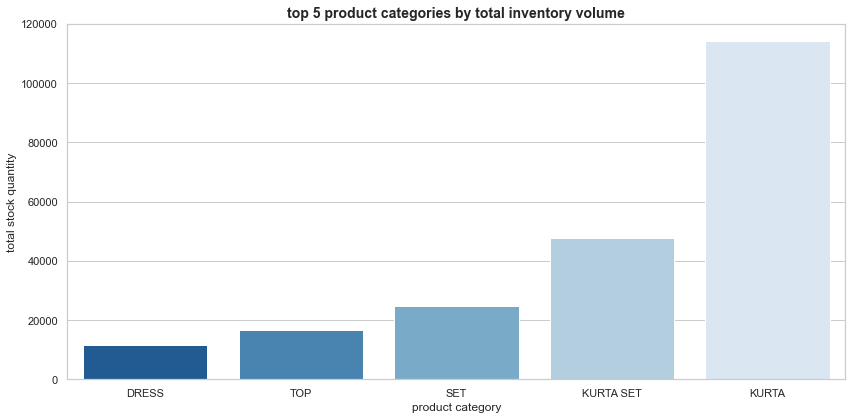

In [12]:
# Visualize the top product categories by total stock volume:

import matplotlib.pyplot as plt
import seaborn as sns

# set style
sns.set_theme(style='whitegrid')

# plot top categories by stock volume:
plt.figure(figsize=(12, 6))
top_chart_data=top_categories_df.sort_values(by='totalstockvolume', ascending=True)

sns.barplot(data=top_chart_data, y='totalstockvolume', x='Category', palette='Blues_r')
plt.title('top 5 product categories by total inventory volume', fontweight='bold', fontsize=14)
plt.ylabel('total stock quantity', fontsize=12)
plt.xlabel('product category', fontsize=12)
plt.tight_layout()
plt.show()

